> **UNQUANTIZED RERUN** — generated copy of `22_e3_negative_steering.ipynb` with
> `meta-llama/Llama-3.1-8B-Instruct` (bf16, sharded via `device_map="auto"`)
> in place of the AWQ-INT4 variant. All `resources/` outputs carry the
> `_unquantized` suffix; the pair selection (`15_e0_selected_pairs.json`) is
> shared with the quantized runs so results are directly comparable.
> Hardcoded reference values quoted in comments/markdown still describe the
> AWQ runs. Original notebook left untouched.


# 21 — E3: negative / mixed steering

One **attracted** + one **repelled** concept, on the three E0 ρ strata, both
directions per pair, at the E1 operating point (k=4, steps=24, shared 20-prompt
suite and baselines):

| method | space | composition |
|---|---|---|
| `attract-only` | — | vanilla CGD on the attract concept (control: measures *incidental* expression of the repelled concept) |
| `frame-diff` | frame | guide = attract − repel (the paper's differential guidance; identical to `Concept.average(weights=[1,−1])` — Step 5) |
| `score-neg` | score | per-step z-scored weighted sum with weights [1, −1] |

Unnormalized score-space `[1, −1]` is provably identical to `frame-diff`
(linearity confound, Step 4), so it is not run.

**Success here is two-sided:** Δexpr(attract) > 0 AND Δexpr(repel) < 0.
The quantities of interest are suppression (−Δrepel) beyond what attract-only
already buys incidentally, and whether frame- or score-space buys it cheaper
in fluency. The high-ρ stratum (near-synonyms sorrow/sadness) is the hard case:
suppressing a concept while expressing its geometric twin.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.representations import FrameUnembeddingRepresentation

In [2]:
fur = FrameUnembeddingRepresentation.from_model_id(
    "meta-llama/Llama-3.1-8B-Instruct",
    device_map="auto",
    torch_dtype=torch.bfloat16,
)

MIN_LEMMAS = 11
MAX_TOKENS = 3
K = 4
STEPS = 24

SELECTION = json.loads(Path("resources/15_e0_selected_pairs.json").read_text())[
    "selected"
]
for stratum, info in SELECTION.items():
    print(f"{stratum:>6}: {info['a']} / {info['b']}  rho={info['rho']:.3f}")

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


2026-07-17 00:32:07.163 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: meta-llama/Llama-3.1-8B-Instruct


2026-07-17 00:32:07.166 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 15316 Mb


   low: sadness.n.01 / music.n.01  rho=0.187
medium: woman.n.01 / king.n.01  rho=0.321
  high: sorrow.n.01 / sadness.n.01  rho=0.566


In [3]:
def chat(user: str, assistant: str = "") -> str:
    return (
        f"<|start_header_id|>user<|end_header_id|>{user}<|eot_id|>"
        f"<|start_header_id|>assistant<|end_header_id|>{assistant}"
    )


# Same suite as 20_e1_family_sweep — keeps E1/E3 rows directly comparable.
PROMPTS = [
    chat("What men can be?", "1."),
    chat("What women can be?", "1."),
    chat("Tell me a short story.", "Once"),
    chat("Describe your favorite place.", "My favorite place is"),
    chat("What do you like to do on weekends?", "I like"),
    chat("Give me some advice for a good life.", "1."),
    chat(
        "What is the most important thing in the world?", "The most important thing is"
    ),
    chat("Describe the weather today.", "Today the weather is"),
    chat("What should I cook for dinner?", "You should"),
    chat("Name things that make people happy.", "1."),
    chat("What did you do today?", "Today I"),
    chat("Describe a memorable meal.", "The most memorable meal"),
    chat("What is a good gift idea?", "A good gift"),
    chat("Describe your hometown.", "My hometown is"),
    chat("Tell me about your favorite season.", "My favorite season is"),
    chat("What makes a good friend?", "A good friend"),
    chat("Describe a place you would like to visit.", "I would like to visit"),
    chat("What do you do to relax?", "To relax, I"),
    chat("Tell me something interesting.", "Here is something interesting:"),
    chat("Describe your morning routine.", "My morning starts"),
]

LOG_PATH = Path("resources/22_e3_negative_unquantized.jsonl")
LOG_PATH.unlink(missing_ok=True)

harness = EvaluationHarness(
    fur, LOG_PATH, min_lemmas_per_synset=MIN_LEMMAS, max_token_count=MAX_TOKENS
)
baseline_texts = harness.generate_baseline(PROMPTS, max_new_tokens=STEPS + 2)
print("baseline ready")

  0%|          | 0/1 [00:00<?, ?it/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


100%|██████████| 1/1 [00:01<00:00,  1.64s/it]

100%|██████████| 1/1 [00:01<00:00,  1.64s/it]

baseline ready


In [4]:
FAMILY = {
    "attract-only": "control",
    "frame-diff": "frame",
    "score-neg": "score",
}


def make_methods(attract, repel) -> dict:
    differential = attract - repel  # Procrustes projection of the difference
    return {
        "attract-only": lambda: fur.generate_with_topk_guide(
            PROMPTS, guide=attract, k=K, steps=STEPS
        ),
        "frame-diff": lambda: fur.generate_with_topk_guide(
            PROMPTS, guide=differential, k=K, steps=STEPS
        ),
        "score-neg": lambda: fur.generate_with_topk_multi_guide(
            PROMPTS,
            guides=[attract, repel],
            weights=[1.0, -1.0],
            k=K,
            steps=STEPS,
            normalize="zscore",
        ),
    }

In [5]:
for stratum, info in SELECTION.items():
    concept = {
        name: fur.get_concept_cached(name, MIN_LEMMAS, MAX_TOKENS)
        for name in (info["a"], info["b"])
    }

    for attract_name, repel_name in ((info["a"], info["b"]), (info["b"], info["a"])):
        methods = make_methods(concept[attract_name], concept[repel_name])
        for method, generate in methods.items():
            torch.cuda.empty_cache()
            texts, probe = generate()
            harness.evaluate(
                PROMPTS,
                texts,
                [attract_name, repel_name],
                config={
                    "stratum": stratum,
                    "rho": info["rho"],
                    "method": method,
                    "family": FAMILY[method],
                    "attract": attract_name,
                    "repel": repel_name,
                    "k": K,
                    "steps": STEPS,
                },
                probe=probe,
                baseline_texts=baseline_texts,
                concepts=concept,
            )
            print(f"{stratum} / +{attract_name} -{repel_name} / {method}: done")

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:15<00:00, 15.85s/it]

100%|██████████| 1/1 [00:15<00:00, 15.85s/it]

low / +sadness.n.01 -music.n.01 / attract-only: done


  0%|          | 0/1 [00:00<?, ?it/s]

...

high / +sadness.n.01 -sorrow.n.01 / frame-diff: done


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:16<00:00, 16.03s/it]

100%|██████████| 1/1 [00:16<00:00, 16.03s/it]

high / +sadness.n.01 -sorrow.n.01 / score-neg: done


In [6]:
parsed = [json.loads(line) for line in LOG_PATH.read_text().strip().split("\n")]
assert len(parsed) == 3 * 2 * len(FAMILY) * len(PROMPTS), "3 strata x 2 dir x methods"
assert all(r["expression"] is not None for r in parsed), "metric v2 present everywhere"
print(f"gate: {len(parsed)} records parse, expression logged")

gate: 360 records parse, expression logged


In [7]:
rows = []
for record in parsed:
    config = record["config"]
    expr = record["expression"]
    delta_attract = expr[config["attract"]]["delta"]
    delta_repel = expr[config["repel"]]["delta"]
    rows.append(
        {
            "stratum": config["stratum"],
            "rho": config["rho"],
            "method": config["method"],
            "attract": config["attract"],
            "repel": config["repel"],
            "direction": f"+{config['attract'].split('.')[0]}"
            f"-{config['repel'].split('.')[0]}",
            "delta_attract": delta_attract,
            "delta_repel": delta_repel,
            "net": delta_attract - delta_repel,
            "clean": delta_attract > 0 and delta_repel < 0,
            "ppl_ratio": record["ppl_ratio"],
            "fluency_flag": record["fluency_flag"],
        }
    )
results = pd.DataFrame(rows)

summary = (
    results.groupby(["stratum", "rho", "direction", "method"])
    .agg(
        delta_attract=("delta_attract", "mean"),
        delta_repel=("delta_repel", "mean"),
        net=("net", "mean"),
        clean_rate=("clean", "mean"),
        ppl_ratio=("ppl_ratio", "mean"),
        flag_share=("fluency_flag", "mean"),
    )
    .reset_index()
    .sort_values(["rho", "direction", "net"], ascending=[True, True, False])
)
summary.to_csv("resources/22_e3_summary_unquantized.csv", index=False)
summary.round(4)

,stratum,rho,direction,method,delta_attract,delta_repel,net,clean_rate,ppl_ratio,flag_share
7,low,0.1867,+music-sadness,frame-diff,0.2584,-0.6766,0.9350,0.40,7.8359,0.90
8,low,0.1867,+music-sadness,score-neg,-0.0103,-0.7410,0.7307,0.40,6.3334,0.90
6,low,0.1867,+music-sadness,attract-only,0.5068,0.1702,0.3366,0.15,6.9705,0.90
10,low,0.1867,+sadness-music,frame-diff,0.2215,-1.1687,1.3902,0.40,8.5043,0.95
11,low,0.1867,+sadness-music,score-neg,0.3014,-0.9469,1.2483,0.45,10.0560,0.90
9,low,0.1867,+sadness-music,attract-only,0.9178,-0.1096,1.0275,0.40,7.2147,0.85
14,medium,0.3213,+king-woman,score-neg,-0.5769,-0.9544,0.3775,0.10,9.2919,0.90
13,medium,0.3213,+king-woman,frame-diff,-0.3021,-0.6607,0.3586,0.10,7.5355,0.85
12,medium,0.3213,+king-woman,attract-only,0.4910,0.3080,0.1830,0.10,6.9849,0.90
17,medium,0.3213,+woman-king,score-neg,-0.2400,-0.9174,0.6774,0.30,10.2930,0.90


## Quadrant view

x = Δexpr(repelled), y = Δexpr(attracted); each point is one (direction, method)
cell mean. The target quadrant is **top-left** (attract up, repel below
baseline). `attract-only` shows where steering lands with no repulsion at all —
the other two methods must beat it leftward without giving up height.

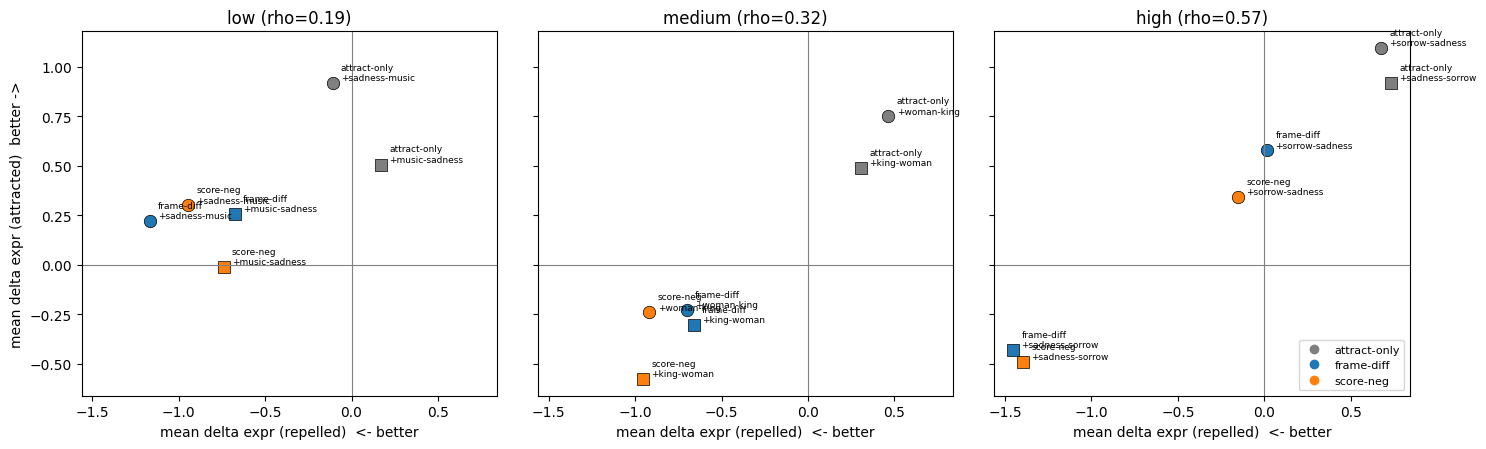

In [8]:
method_colors = {
    "attract-only": "tab:gray",
    "frame-diff": "tab:blue",
    "score-neg": "tab:orange",
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True, sharey=True)
for ax, (stratum, info) in zip(axes, SELECTION.items()):
    cell = summary[summary["stratum"] == stratum]
    for _, row in cell.iterrows():
        marker = (
            "o" if row["direction"].startswith(f"+{info['a'].split('.')[0]}") else "s"
        )
        ax.scatter(
            row["delta_repel"],
            row["delta_attract"],
            s=80,
            marker=marker,
            color=method_colors[row["method"]],
            edgecolor="black",
            linewidth=0.5,
        )
        ax.annotate(
            f"{row['method']}\n{row['direction']}",
            (row["delta_repel"], row["delta_attract"]),
            textcoords="offset points",
            xytext=(6, 2),
            fontsize=6.5,
        )
    ax.axhline(0, color="gray", lw=0.8)
    ax.axvline(0, color="gray", lw=0.8)
    ax.set_title(f"{stratum} (rho={info['rho']:.2f})")
    ax.set_xlabel("mean delta expr (repelled)  <- better")
axes[0].set_ylabel("mean delta expr (attracted)  better ->")

handles = [
    plt.Line2D([], [], marker="o", ls="", color=c, label=m)
    for m, c in method_colors.items()
]
axes[-1].legend(handles=handles, fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig("resources/22_e3_quadrants_unquantized.png", dpi=150)
plt.show()

In [9]:
# Paired per-prompt suppression: does either negative method push the repelled
# concept below attract-only's incidental level, on the same prompt?
paired = results.pivot_table(
    index=["stratum", "direction", "attract", "repel"],
    columns="method",
    values="delta_repel",
    aggfunc=list,
)
print("suppression vs attract-only control (paired per prompt):")
for method in ("frame-diff", "score-neg"):
    for (stratum, direction, _, _), row in paired.iterrows():
        control, treated = pd.Series(row["attract-only"]), pd.Series(row[method])
        wins = int((treated < control).sum())
        print(
            f"  {stratum:>6} {direction:>18} {method:>10}: "
            f"{wins:>2}/{len(treated)} prompts more suppressed, "
            f"mean gap {(treated - control).mean():+.3f}"
        )

suppression vs attract-only control (paired per prompt):
    high    +sadness-sorrow frame-diff: 19/20 prompts more suppressed, mean gap -2.187
    high    +sorrow-sadness frame-diff: 14/20 prompts more suppressed, mean gap -0.658
     low     +music-sadness frame-diff: 16/20 prompts more suppressed, mean gap -0.847
     low     +sadness-music frame-diff: 18/20 prompts more suppressed, mean gap -1.059
  medium        +king-woman frame-diff: 18/20 prompts more suppressed, mean gap -0.969
  medium        +woman-king frame-diff: 18/20 prompts more suppressed, mean gap -1.169
    high    +sadness-sorrow  score-neg: 20/20 prompts more suppressed, mean gap -2.131
    high    +sorrow-sadness  score-neg: 19/20 prompts more suppressed, mean gap -0.826
     low     +music-sadness  score-neg: 17/20 prompts more suppressed, mean gap -0.911
     low     +sadness-music  score-neg: 19/20 prompts more suppressed, mean gap -0.837
  medium        +king-woman  score-neg: 19/20 prompts more suppressed, me

In [10]:
def answer(text: str) -> str:
    return text.split("assistant<|end_header_id|>")[-1]


for stratum in SELECTION:
    for method in FAMILY:
        example = next(
            r
            for r in parsed
            if r["config"]["stratum"] == stratum
            and r["config"]["method"] == method
            and "short story" in r["prompt"]
        )
        config = example["config"]
        deltas = {
            name.split(".")[0]: round(v["delta"], 3)
            for name, v in example["expression"].items()
        }
        print(
            f"[{stratum} / +{config['attract'].split('.')[0]}"
            f"-{config['repel'].split('.')[0]} / {method}] deltas={deltas}"
        )
        print("   ", answer(example["text"])[:130])
    print()

[low / +sadness-music / attract-only] deltas={'sadness': 0.525, 'music': -1.078}
    Once, on an old and cypress-kisséd bayous in Louisiana there existed an enchanté woman with skin as black as
[low / +sadness-music / frame-diff] deltas={'sadness': 0.605, 'music': -1.12}
    Once there lived in Japan, a small town nestled at foot hills, surrounded on three-sids, and overlooking vast ex-panse
[low / +sadness-music / score-neg] deltas={'sadness': -0.022, 'music': -1.673}
    Once there were twin brothers who lived a humble but happy lives on opposite coaxes of an old, gnarling oak tree.

[medium / +woman-king / attract-only] deltas={'woman': 0.27, 'king': -0.109}
    Once, a young artist lived alone above his art supply storefront in Paris' Montmatré quarter. The smell from turpenoid
[medium / +woman-king / frame-diff] deltas={'woman': 0.359, 'king': -0.631}
    Once there was an elderly watch repair shop owner, named Emilia, whose small business was tucked between an old antique store a